# 五类分类方法与训练过程
朴素贝叶斯和逻辑回归共享词 TF-IDF，SVM 加入字符与主题。Qwen 冻结编码器学习分类头，MacBERT 全量微调。以下是开发过程，不把 Tune 当 Test。

In [1]:
from pathlib import Path
import os,json
if not Path('configs').exists() and Path('../configs').exists():os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from spam_analysis.analysis.results import source_records,result_table,error_frame
from spam_analysis.experiments.runtime import ExperimentSession
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False
engine=ExperimentSession()
print('结果版本：',engine.run_id)


结果版本： course-20261016


In [2]:
run=Path('artifacts/runs')/engine.run_id
for filename in ['sparse_training.csv','qwen_training.csv','main_selection.csv']:
    path=run/filename
    if path.exists():print(filename);display(pd.read_csv(path))
    else:print(filename,'尚未完成')

sparse_training.csv


,model,fit_s,dimensions,tn,fp,fn,tp,accuracy,spam_precision,spam_recall,...,ham_f1,macro_f1,balanced_accuracy,ham_fpr,spam_miss_rate,n,threshold,average_precision,roc_auc,brier
0,B1,130.341975,100000,4154.0,92.0,581.0,5941.0,0.937500,0.984751,0.910917,...,0.925064,0.935730,0.944625,0.021667,0.089083,10768,0.0,0.994335,0.992179,NaN
1,B2,61.825834,100000,4173.0,73.0,36.0,6486.0,0.989877,0.988870,0.994480,...,0.987108,0.989388,0.988644,0.017193,0.005520,10768,0.0,0.999513,0.999227,NaN
2,S_char13,339.312148,330000,4214.0,32.0,23.0,6499.0,0.994892,0.995100,0.996473,...,0.993516,0.994651,0.994468,0.007537,0.003527,10768,0.0,0.999822,0.999729,NaN


qwen_training.csv


,C,fit_s,tn,fp,fn,tp,accuracy,spam_precision,spam_recall,spam_f1,...,ham_f1,macro_f1,balanced_accuracy,ham_fpr,spam_miss_rate,n,threshold,average_precision,roc_auc,brier
0,0.1,0.789124,3982.0,264.0,217.0,6305.0,0.955331,0.959811,0.966728,0.963257,...,0.943043,0.953150,0.952276,0.062176,0.033272,10768,0.0,0.994889,0.992181,NaN
1,1.0,1.121296,4061.0,185.0,159.0,6363.0,0.968053,0.971747,0.975621,0.973680,...,0.959367,0.966524,0.966025,0.043570,0.024379,10768,0.0,0.996957,0.995438,NaN
2,10.0,0.898480,4086.0,160.0,162.0,6360.0,0.970097,0.975460,0.975161,0.975311,...,0.962091,0.968701,0.968739,0.037683,0.024839,10768,0.0,0.997186,0.995907,NaN


main_selection.csv


,model,eligible,tn,fp,fn,tp,accuracy,spam_precision,spam_recall,spam_f1,...,ham_f1,macro_f1,balanced_accuracy,ham_fpr,spam_miss_rate,n,threshold,average_precision,roc_auc,brier
0,B1,True,4105.0,204.0,111.0,6767.0,0.971842,0.970736,0.983862,0.977255,...,0.963050,0.970152,0.968259,0.047343,0.016138,11187,0.492895,0.994682,0.992117,0.025802
1,B2,True,4259.0,50.0,58.0,6820.0,0.990346,0.992722,0.991567,0.992144,...,0.987480,0.989812,0.989982,0.011604,0.008433,11187,0.666577,0.999165,0.998812,0.008448
2,S_char13,True,4273.0,36.0,42.0,6836.0,0.993028,0.994761,0.993894,0.994327,...,0.990955,0.992641,0.992769,0.008355,0.006106,11187,0.598626,0.999371,0.998915,0.006358
3,E1,True,4133.0,176.0,160.0,6718.0,0.969965,0.974471,0.976737,0.975603,...,0.960939,0.968271,0.967946,0.040845,0.023263,11187,0.560614,0.997540,0.996154,0.022622
4,E2,True,4288.0,21.0,18.0,6860.0,0.996514,0.996948,0.997383,0.997165,...,0.995473,0.996319,0.996255,0.004874,0.002617,11187,0.203658,0.999816,0.999767,0.003238


,loss_mode,lr,epoch,training_loss,training_s,peak_allocated_mib,train_rows,tn,fp,fn,...,ham_f1,macro_f1,balanced_accuracy,ham_fpr,spam_miss_rate,n,threshold,average_precision,roc_auc,brier
0,ordinary,0.00002,1,0.095804,1058.844,3463.236328,60497,4144.0,102.0,9.0,...,0.986784,0.989167,0.987299,0.024023,0.001380,10768,0.0,0.999707,0.999580,NaN
1,ordinary,0.00002,2,0.017659,1055.922,3460.697266,60497,4217.0,29.0,33.0,...,0.992702,0.993974,0.994055,0.006830,0.005060,10768,0.0,0.999846,0.999771,NaN
2,ordinary,0.00002,3,0.004807,1062.359,3464.923828,60497,4222.0,24.0,39.0,...,0.992594,0.993879,0.994184,0.005652,0.005980,10768,0.0,0.999915,0.999871,NaN
3,ordinary,0.00003,1,0.090534,1067.813,3492.658203,60497,4191.0,55.0,23.0,...,0.990780,0.992408,0.991760,0.012953,0.003527,10768,0.0,0.999618,0.999506,NaN
4,ordinary,0.00003,2,0.017626,1030.313,3466.111328,60497,4207.0,39.0,29.0,...,0.991983,0.993387,0.993184,0.009185,0.004446,10768,0.0,0.999855,0.999786,NaN
5,ordinary,0.00003,3,0.004458,1034.047,3471.923828,60497,4225.0,21.0,36.0,...,0.993300,0.994462,0.994767,0.004946,0.005520,10768,0.0,0.999870,0.999810,NaN
6,balanced,0.00002,1,0.101391,1062.125,3489.435547,60497,4185.0,61.0,28.0,...,0.989479,0.991336,0.990670,0.014366,0.004293,10768,0.0,0.999611,0.999466,NaN
7,balanced,0.00002,2,0.020072,1039.235,3493.548828,60497,4198.0,48.0,18.0,...,0.992200,0.993576,0.992968,0.011305,0.002760,10768,0.0,0.999883,0.999822,NaN
8,balanced,0.00002,3,0.004361,1014.797,3491.205078,60497,4225.0,21.0,32.0,...,0.993767,0.994850,0.995074,0.004946,0.004906,10768,0.0,0.999926,0.999888,NaN
9,balanced,0.00003,1,0.096306,975.094,3489.365234,60497,4202.0,44.0,39.0,...,0.990220,0.991930,0.991829,0.010363,0.005980,10768,0.0,0.999734,0.999603,NaN


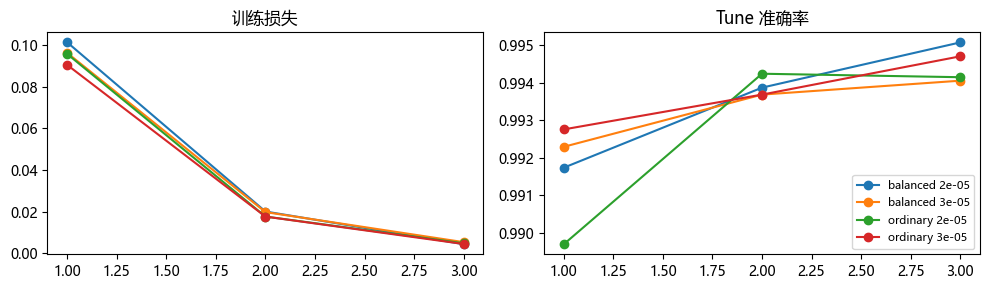

In [3]:
path=run/'training_curves.csv'
if path.exists():
    curves=pd.read_csv(path);display(curves)
    fig,axes=plt.subplots(1,2,figsize=(10,3))
    for (mode,lr),g in curves.groupby(['loss_mode','lr']):
        axes[0].plot(g.epoch,g.training_loss,marker='o',label=f'{mode} {lr:g}')
        axes[1].plot(g.epoch,g.accuracy,marker='o',label=f'{mode} {lr:g}')
    axes[0].set_title('训练损失');axes[1].set_title('Tune 准确率');axes[1].legend(fontsize=8);plt.tight_layout();plt.show()
else:print('神经训练尚未生成完整轮次记录')

In [4]:
conditions=[]
for name in ['B1','B2','S_char13','E1','E2']:
    item=engine.entries[name]
    conditions.append({'方法':name,'训练样本':item.get('train_rows','见基线记录'),'训练先验':item.get('train_prior'),'模型身份':item['model_sha256'][:12]})
display(pd.DataFrame(conditions))

,方法,训练样本,训练先验,模型身份
0,B1,60497,0.624593,672e695bb62b
1,B2,60497,0.624593,286ebde26af0
2,S_char13,60497,0.624593,340264a366d2
3,E1,60497,0.624593,706b293fd090
4,E2,60497,0.624593,b99ea5b29944


比较完整方案，参数量和输入长度并不相同。模型选择依据开发数据；数据增多不保证效果提高。GPU 断点保存优化器、随机状态与批次位置，避免中断后把不同训练过程混为一次。